# Imports, Pathway, and reading csv file for base dataset

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from math import ceil


PROJECT_ROOT =Path.cwd().parent.parent

INPUT_PATH = PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv"

popularity_dataset = pd.read_csv(INPUT_PATH)

08_popularity_features.csv , has genre_count, target_log_popularity,has_collectionm, country_count,company_count,spoken_language_count so we are using that file.


In [127]:
popularity_dataset.columns

Index(['id', 'target_log_popularity', 'release_year', 'release_month',
       'release_decade', 'log_budget', 'log_revenue', 'runtime', 'genre_count',
       'has_collection', 'company_count', 'country_count',
       'spoken_language_count', 'cast_size', 'crew_size', 'has_director',
       'keyword_count', 'title_word_count', 'overview_word_count',
       'title_differs_from_original', 'genres', 'production_companies',
       'production_countries', 'spoken_languages', 'director', 'top_cast',
       'keywords', 'title', 'original_title', 'overview', 'original_language',
       'status', 'budget_reported', 'revenue_reported'],
      dtype='str')

created a variable to store my series object of genre_count and target_log_popularity

In [128]:
gc_series = popularity_dataset['genre_count']
tlp_series = popularity_dataset['target_log_popularity']

### Create Scatter plot of `genre_count` vs. `target_log_popularity`
- Explores the relationship of # of genres a movie and its popularity
- X-axis represents popularity from the range 0-7
- Y-axis represents genre from the range of 0-9
- Each point represents a movie

The goal is to see if movies with more genres tend to be more popular and we can see that 3 is the sweetspot. 

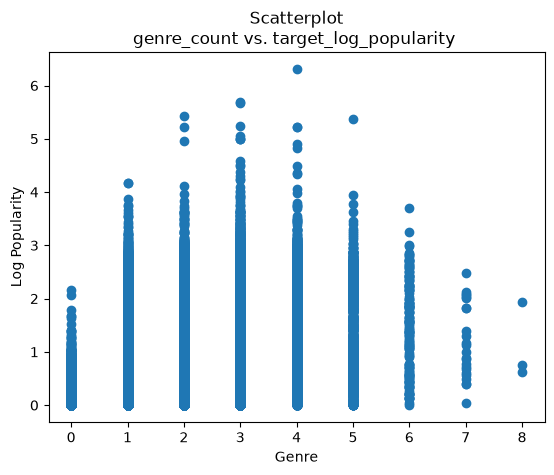

In [129]:
x1 = np.array([gc_series]) # X is our genre count which is 0-8 on the x axis.
y1 = np.array([tlp_series]) # Y is our target_log_popularity which is 0-6 on the y-axis.

plt.title('Scatterplot\ngenre_count vs. target_log_popularity ')
plt.scatter(x1,y1,label="Count")
plt.xlabel('Genre') #X-axis
plt.ylabel('Log Popularity') #Y-axis
plt.show()

In [130]:
hc_series = popularity_dataset['has_collection']



### Scatterplot comparison for popularity if movie has collection or not
- Explores the relationship of popularity for movies that have acollection or not. 
- Y-axis represent the popularity with the range of 0-9
- X-axis represents if it has a collection or not it's binary and the range is 0-1 with 0 representing no and 1 representing yes.
- Each point represents a movies
- Most points are bunched uop between 3-4 on the no column.

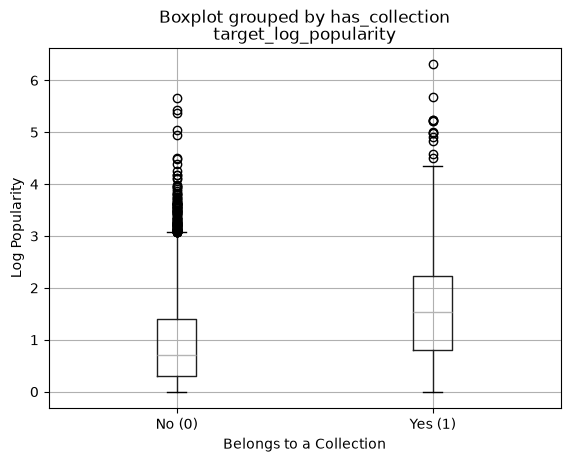

In [131]:
popularity_dataset.boxplot(column = 'target_log_popularity' , by = 'has_collection')
plt.xticks([1,2], ['No (0)', 'Yes (1)'])
plt.xlabel('Belongs to a Collection')
plt.ylabel('Log Popularity')
plt.show()

### Scatterplot `company_count` vs. `target_log_popularity`

- Explores the relationship between production companies that were involved in the movie with the popularity of the movie
- X-axis represents company count with the range being from 0-25
- Y-axis represents the popularity of the movie
- Each point represents a movie

The goal is to see the popularity of the movie depending how many production companies were involved for the movie.

<function matplotlib.pyplot.show(close=None, block=None)>

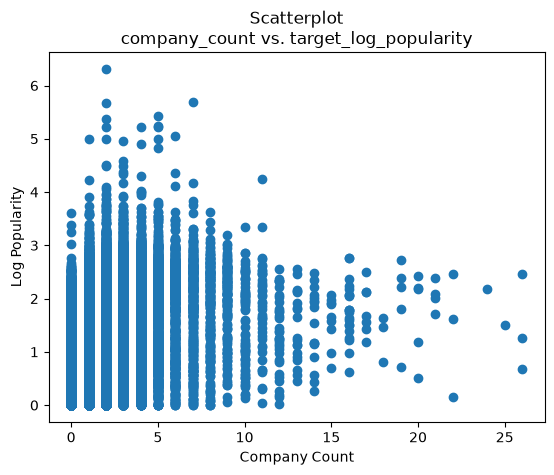

In [132]:
cc_series = popularity_dataset['company_count']
x2 = np.array([cc_series])
y2 = np.array([tlp_series])

plt.title('Scatterplot\ncompany_count vs. target_log_popularity')
plt.scatter(x2,y2)
plt.xlabel('Company Count')
plt.ylabel('Log Popularity')
plt.show

### Scatterplot `country_count` vs. `target_log_popularity`

- Explores the relationship between the amount of countries it took to produce a movie and with it's popularity
- Y-axis represents the popularity with the range of 0-7
- X-axis represents the company count with the range of 0-26
- Each point represents a movie

The goal is to see the popularity of the movie with the amount of countries it took to produce the movie.

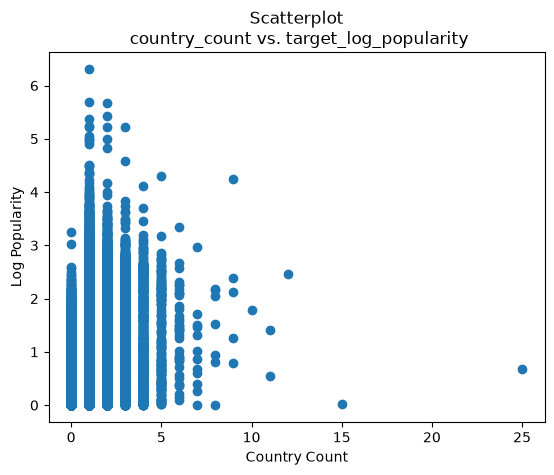

In [172]:
countc_series = popularity_dataset['country_count']

x3 = np.array([countc_series])
y3 = np.array([tlp_series])


plt.title('Scatterplot\n country_count vs. target_log_popularity')
plt.scatter(x3,y3,)
plt.xlabel('Country Count')
plt.ylabel('Log Popularity')

plt.show()

### Scatterplot `spoken_language_count` vs. `target_log_popularity`

- Explores the relationship of the movie 
- X-axis representing the spoken language count with the range of 0-18
- Y-axis representing the popularity count with the range of 0-7
- Each point represents a movie
- A bunch of the movies are bunched up between y(0-3), and x(0-5)

The goal is to see popularity of movies with the number of languages spoken during the movie.

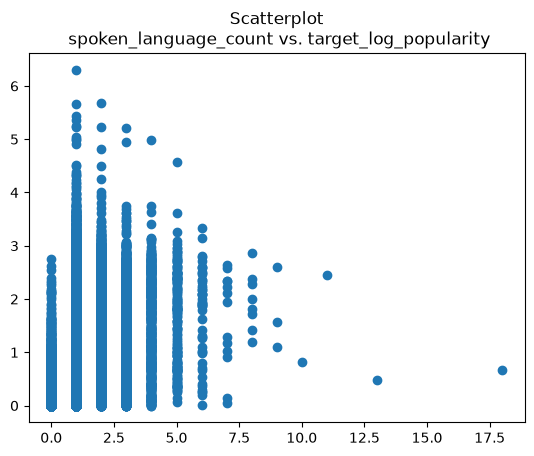

In [134]:
slc_series = popularity_dataset['spoken_language_count']

x4 = np.array([slc_series])
y4 = np.array([tlp_series])

plt.title('Scatterplot\n spoken_language_count vs. target_log_popularity')
plt.scatter(x4,y4)
plt.show()

### Additional visualizations added `heatmaps` 

- Redid all the scatterplots/box plot into heatmaps
- same range for x-axis and y-axis with a colorbar on the side that determines the amount of movies
- displays hot spots in the y-axis from 1-3 where majority of the movies are displayed on there.
- shows the count of the amount of movies in certain bounds

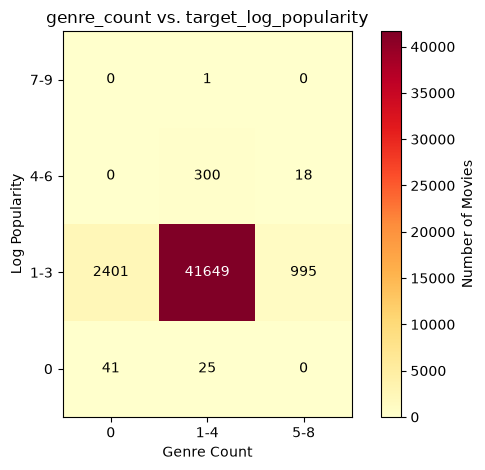

In [ ]:

# Four rows and three columns
counts = [[0] * 3 for _ in range(4)]

#reads each movie's genre coutn and popularity
for genre, popularity in zip(
    popularity_dataset['genre_count'],
    popularity_dataset['target_log_popularity']
):
    if 0 <= genre <= 8 and 0 <= popularity <= 9:
        counts[ceil(popularity / 3)][ceil(genre / 4)] += 1

# Create the heatmap
heatmap = plt.imshow(
    counts, origin='lower', cmap='YlOrRd', vmin=0
)

plt.xticks([0, 1, 2], ['0', '1-4', '5-8'])
plt.yticks([0, 1, 2, 3], ['0', '1-3', '4-6', '7-9'])

# Add numbers inside the cells
for row in range(4):
    for col in range(3):
        value = counts[row][col]
        plt.text(
            col, row, str(value),
            ha='center', va='center',
            color='white' if heatmap.norm(value) > 0.5 else 'black'
        )

plt.xlabel("Genre Count")
plt.ylabel("Log Popularity")
plt.title("genre_count vs. target_log_popularity")
plt.colorbar(label="Number of Movies")
plt.tight_layout()
plt.show()

In [140]:
highest_num = popularity_dataset['company_count'].max()
print(highest_num)

26


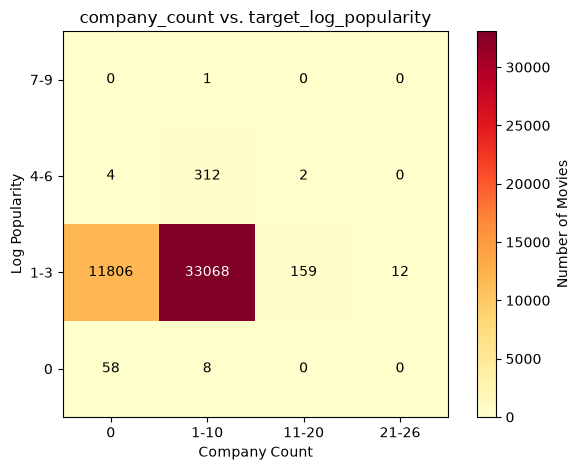

In [ ]:

counts2 = [[0] * 4 for _ in range(4)] #creates four row and four columns grid that is empty

#reads each movie's company and popularity
for company,popularity in zip(
    popularity_dataset['company_count'],
    popularity_dataset['target_log_popularity']
):
    if 0 <= company <= 26 and 0 <= popularity <= 9:
        counts2[ceil(popularity / 3)][ceil(company/10)] +=1

#creates heatmap
heatmap = plt.imshow(
    counts2, origin='lower',cmap='YlOrRd',vmin=0
)


#Labeling bounds with the values and grouping them up with their indices and labeling them what each index represents
plt.xticks([0,1,2,3],['0','1-10','11-20','21-26'])
plt.yticks([0,1,2,3], ['0','1-3','4-6','7-9'])

# visits each cell in the grid and adds a value to them which are the movies
for row in range(4):
    for col in range(4):
        value = counts2[row][col]
        plt.text(
            col,row,str(value),
            ha='center',va='center',
            color='white' if heatmap.norm(value) > 0.5 else 'black'
        )

#labeling the heatmap and displays it
plt.xlabel("Company Count")
plt.ylabel("Log Popularity")
plt.title("company_count vs. target_log_popularity")
plt.colorbar(label ="Number of Movies")
plt.tight_layout()
plt.show()

In [145]:
highest_num = popularity_dataset['country_count'].max()
print(highest_num)

25


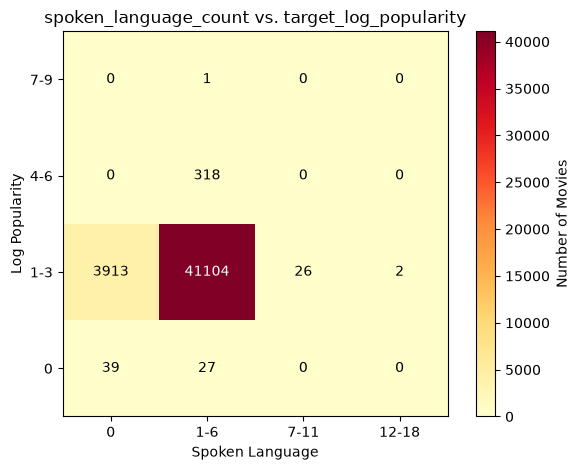

In [ ]:
counts3 = [[0]* 4 for _ in range(4)] #creates 4 row and 4 column grid that is empty

#reads spoken language count and popularity from each movie.
for spoken,popularity in zip(
    popularity_dataset['spoken_language_count'],
    popularity_dataset['target_log_popularity']
):
    if 0 <= spoken <= 18 and 0 <= popularity <=9:
        counts3[ceil(popularity/3)][ceil(spoken/6)] +=1

#creates heatmap
heatmap = plt.imshow(
    counts3, origin='lower' ,cmap='YlOrRd',vmin=0
)

plt.xticks([0,1,2,3],['0','1-6','7-11','12-18'])
plt.yticks([0,1,2,3], ['0','1-3','4-6','7-9'])

# visits each cell in the grid and adds a value to them which are the movies
for row in range(4):
    for col in range(4):
        value = counts3[row][col]
        plt.text(
            col,row,str(value),
            ha='center',va='center',
            color='white' if heatmap.norm(value) >0.5 else'black'
        )

#labeling the heatmap and displays it
plt.xlabel('Spoken Language')
plt.ylabel('Log Popularity')
plt.title("spoken_language_count vs. target_log_popularity")
plt.colorbar(label = 'Number of Movies')
plt.tight_layout()
plt.show()

In [ ]:
highest_num= popularity_dataset['spoken_language_count'].max() #looking for highest vlaue to establish the bounds
print(highest_num)

highest_num2 = popularity_dataset['country_count'].max()
print(highest_num2) #prints 25 to define bounds

18
25


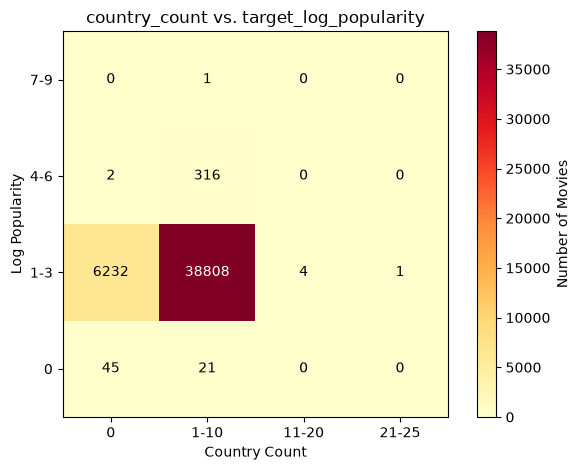

In [ ]:
counts4 = [[0] *4 for _ in range(4)] #creating 4x4 grid heatmap

#reads each movie's country count and popularity
for country,popularity in zip(
    popularity_dataset['country_count'],
    popularity_dataset['target_log_popularity']
):
    #making bounds for each axis
    if 0 <= country <= 25 and 0 <= popularity <= 9:
        counts4[ceil(popularity/3)][ceil(country/10)] +=1

#creating heatmap
heatmap = plt.imshow(
    counts4, origin = 'lower' , cmap='YlOrRd', vmin=0
)
#labeling the bounds 
plt.xticks([0,1,2,3] , ['0','1-10','11-20','21-25'])
plt.yticks([0,1,2,3] , ['0','1-3','4-6','7-9'])

# visits each cell in the grid and adds a value to them which are the movies
for row in range(4):
    for col in range(4):
        value = counts4[row][col]
        plt.text(
            col,row,str(value),
            ha='center',va='center',
            color='white' if heatmap.norm(value) > 0.5 else 'black'
        )

#labeling the heatmap and displaying it
plt.xlabel('Country Count')
plt.ylabel('Log Popularity')
plt.title('country_count vs. target_log_popularity')
plt.colorbar(label = 'Number of Movies')
plt.tight_layout()
plt.show()

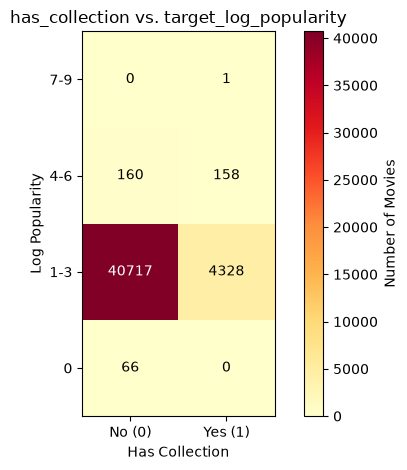

In [173]:
counts5= [[0] * 2 for _ in range(4)] # 2 columns and 4 rows

#reads each movie's collection and popularity
for collection,popularity in zip(
    popularity_dataset['has_collection'],
    popularity_dataset['target_log_popularity']
):
    #displaying bounds
    if 0<= collection <=1 and 0<= popularity <=9:
        counts5[ceil(popularity/3)][int(collection)] +=1

#creates heatmap
heatmap = plt.imshow(counts5,origin='lower',cmap='YlOrRd',vmin=0)

#labeling bounds 
plt.xticks([0,1],['No (0)','Yes (1)'])
plt.yticks([0,1,2,3],['0','1-3','4-6','7-9'])

# visits each cell in the grid and adds a value to them which are the movies
for row in range(4):
    for col in range(2):
        value =counts5[row][col]
        plt.text(
            col,row,str(value),
            ha='center',va='center',
            color='white' if heatmap.norm(value) >0.5 else 'black'
    )

#labeling the heatmap and displaying it
plt.xlabel('Has Collection')
plt.ylabel('Log Popularity')
plt.title('has_collection vs. target_log_popularity')
plt.colorbar(label= 'Number of Movies')
plt.tight_layout()
plt.show()


